In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn import metrics
import seaborn as sns

In [10]:
df=pd.read_csv('/content/drive/MyDrive/Cardiovascular_Disease_Dataset/Cardiovascular_Disease_Dataset.csv')
df

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1


In [11]:
df.corr()

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
patientid,1.000000,0.004978,-0.031263,-0.009679,-0.020926,0.053464,0.022331,-0.003667,-0.036486,0.014338,-0.013825,-0.010128,0.019465,-0.005637
age,0.004978,1.000000,-0.024717,0.037731,-0.016126,0.035439,0.049732,0.067736,-0.040092,-0.037581,-0.026020,-0.015334,0.025407,0.008356
gender,-0.031263,-0.024717,1.000000,0.035402,-0.069727,-0.120759,0.023560,-0.046634,0.064606,-0.051746,0.331457,-0.051957,0.029376,0.015769
chestpain,-0.009679,0.037731,0.035402,1.000000,0.222267,0.174731,0.232059,0.256316,0.114496,-0.027376,0.101345,0.472731,0.285156,0.554228
restingBP,-0.020926,-0.016126,-0.069727,0.222267,1.000000,0.126523,0.192063,0.219887,0.095569,-0.046545,-0.004225,0.376711,0.263194,0.482387
serumcholestrol,0.053464,0.035439,-0.120759,0.174731,0.126523,1.000000,0.278337,0.101767,0.038967,0.029422,-0.025910,0.165569,0.132419,0.195340
fastingbloodsugar,0.022331,0.049732,0.023560,0.232059,0.192063,0.278337,1.000000,0.143982,0.096528,0.011356,0.015311,0.242734,0.182246,0.303233
restingrelectro,-0.003667,0.067736,-0.046634,0.256316,0.219887,0.101767,0.143982,1.000000,0.099991,-0.032489,0.040291,0.343280,0.204684,0.426837
maxheartrate,-0.036486,-0.040092,0.064606,0.114496,0.095569,0.038967,0.096528,0.099991,1.000000,0.015536,0.044614,0.201515,0.122763,0.228343
exerciseangia,0.014338,-0.037581,-0.051746,-0.027376,-0.046545,0.029422,0.011356,-0.032489,0.015536,1.000000,-0.003296,-0.017783,-0.017513,-0.039874


In [23]:
df.drop(['chestpain','serumcholestrol','fastingbloodsugar','restingrelectro','maxheartrate','exerciseangia','oldpeak'],axis=1,inplace=True)

In [24]:
df.head()

,patientid,age,gender,restingBP,slope,noofmajorvessels,target
0,103368,53,1,171,3,3,1
1,119250,40,1,94,1,1,0
2,119372,49,1,133,1,0,0
3,132514,43,1,138,2,2,1
4,146211,31,1,199,3,2,1


<Axes: >

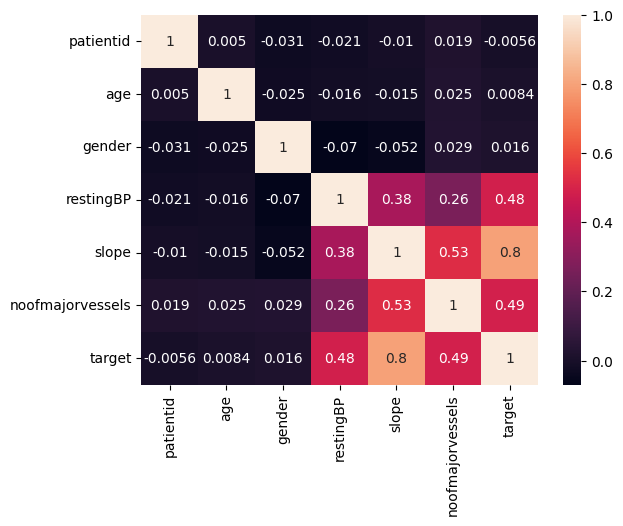

In [25]:
sns.heatmap(df.corr(),annot=True)

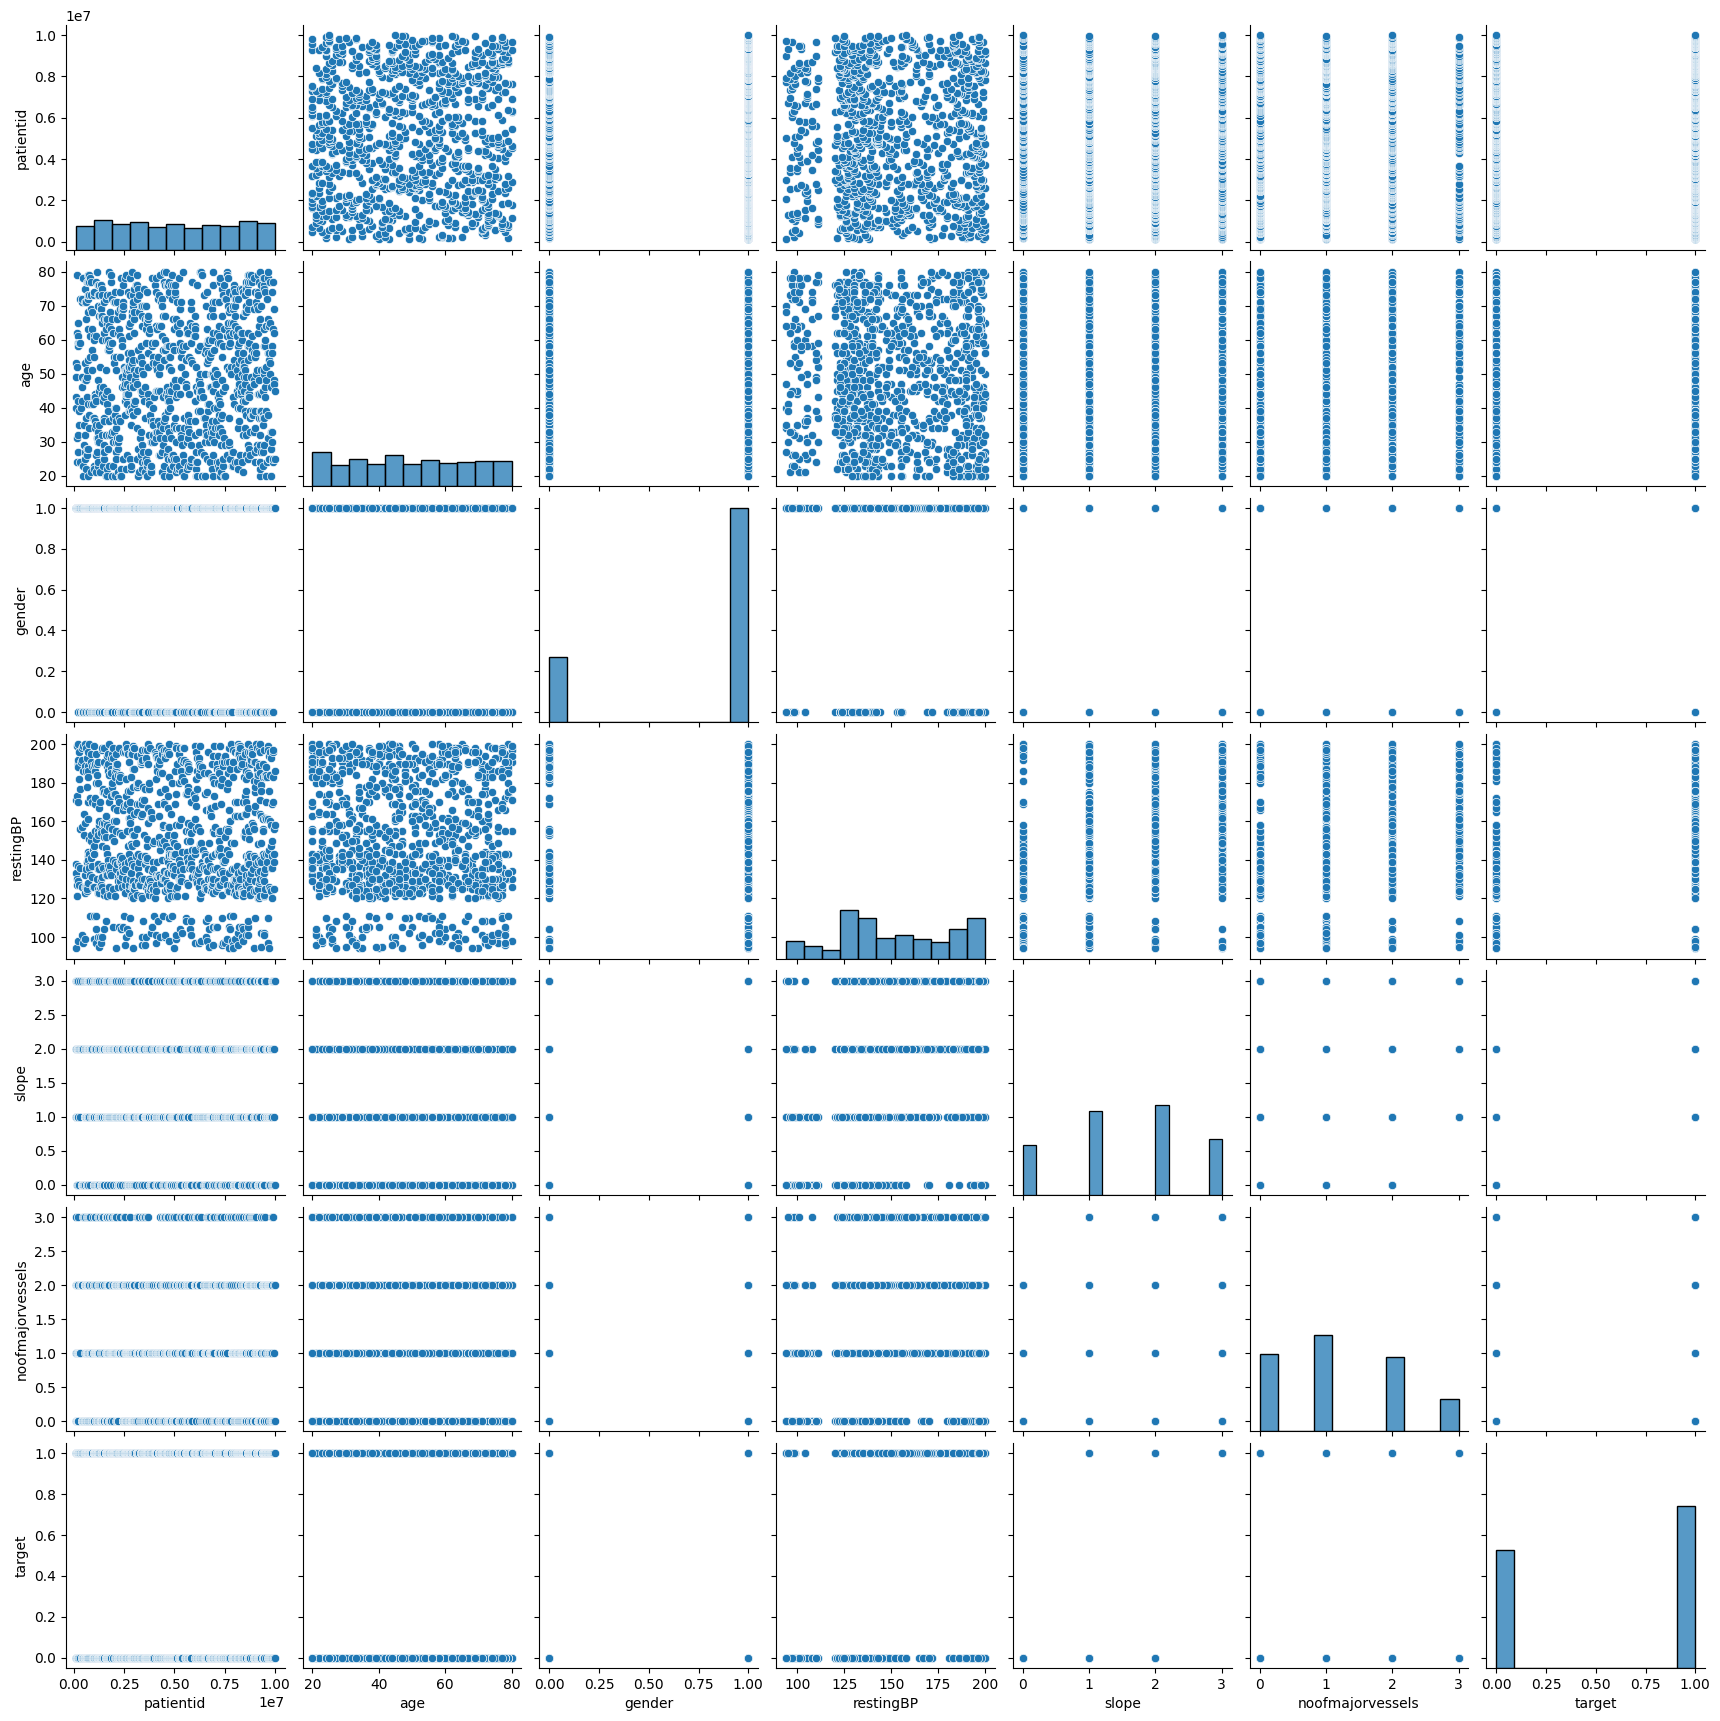

In [26]:
sns.pairplot(df)

In [32]:
y=df['target']

In [27]:
poly=PolynomialFeatures(degree=2,include_bias=False)

In [28]:
polynomialfeatures=poly.fit_transform(df)

In [29]:
polynomialfeatures

array([[1.033680e+05, 5.300000e+01, 1.000000e+00, ..., 9.000000e+00,
        3.000000e+00, 1.000000e+00],
       [1.192500e+05, 4.000000e+01, 1.000000e+00, ..., 1.000000e+00,
        0.000000e+00, 0.000000e+00],
       [1.193720e+05, 4.900000e+01, 1.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00],
       ...,
       [9.965859e+06, 6.900000e+01, 1.000000e+00, ..., 1.000000e+00,
        1.000000e+00, 1.000000e+00],
       [9.988507e+06, 4.500000e+01, 1.000000e+00, ..., 4.000000e+00,
        2.000000e+00, 1.000000e+00],
       [9.990855e+06, 2.500000e+01, 1.000000e+00, ..., 0.000000e+00,
        0.000000e+00, 0.000000e+00]])

In [33]:
x_train,x_test,y_train,y_test=train_test_split(polynomialfeatures,y,test_size=.33,shuffle=False)

In [37]:
reg=LinearRegression()

In [38]:
reg.fit(x_train,y_train)

LinearRegression()

In [39]:
y_pred=reg.predict(x_test)

In [ ]:
pd.DataFrame({'Y_test':y_test,'Y_pred':y_pred,'residuals':(y_test-y_pred)}).head()

,Y_test,Y_pred,residuals
670,1,1.049206,-0.049206
671,0,0.029617,-0.029617
672,1,1.059003,-0.059003
673,0,-0.035019,0.035019
674,0,-0.329340,0.329340


In [ ]:
met_mae = metrics.mean_absolute_error(y_test, y_pred)
met_mse = metrics.mean_squared_error(y_test, y_pred)
pd.DataFrame([met_mae, met_mse], index=['MAE','MSE'], columns=['metrics'])

,metrics
MAE,0.057749
MSE,0.007191
